# 1. Import Libraries and Configure Environment

In [3]:
# ==========================================
# 3.1. Import Libraries and Configure Environment
# ==========================================

# Import standard libraries
import os
import glob
import warnings

# Import data manipulation and numerical libraries
import numpy as np
import pandas as pd

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import image processing libraries
from PIL import Image, ImageFile

# Import display utilities
from IPython.display import display

# Suppress unnecessary warnings
warnings.filterwarnings("ignore")

# Set visualization style
sns.set_theme(style="whitegrid")

# Set random seed for reproducibility
RANDOM_STATE = 42

# Define project directories
PROJECT_PATH = (
    "/content/drive/MyDrive/"
    "HAM10000_Skin_Lesion_Classification"
)

RAW_PATH = os.path.join(PROJECT_PATH, "data/raw")

PROCESSED_PATH = os.path.join(
    PROJECT_PATH, "data/processed"
)

FIGURES_PATH = os.path.join(
    PROJECT_PATH, "reports/figures"
)

# Create output directories if they do not exist
os.makedirs(PROCESSED_PATH, exist_ok=True)
os.makedirs(FIGURES_PATH, exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


# 2. Load Metadata

In [6]:
# ==========================================
# 2. Load Dataset Metadata
# ==========================================

# Define metadata file path
metadata_path = os.path.join(
    RAW_PATH, 'HAM10000_metadata.tab'
)

# Load metadata
df = pd.read_csv(metadata_path, sep='\t')

# Display dataset information
print('Dataset Loaded Successfully')
print('Shape:', df.shape)

# Display the first five records
display(df.head())

Dataset Loaded Successfully
Shape: (10015, 8)


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


# 3. Dataset Structure and Overview

In [10]:
# ==========================================
# 3. Dataset Structure and Overview
# ==========================================
# Check dataset dimentions
print('Dataset Shape:')
print(df.shape)

# Display column names
print('\nColumn Names:')
print(df.columns.tolist())

# Check dataset types
print('\nData Types:')
print(df.dtypes)

# Display dataset information
print('\nDataset Information:')
df.info()

# Generate descriptive statistics
print('\nStatistical Summary:')
display(df.describe(include='all').T)

Dataset Shape:
(10015, 8)

Column Names:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset']

Data Types:
lesion_id        object
image_id         object
dx               object
dx_type          object
age             float64
sex              object
localization     object
dataset          object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
 7   dataset       10015 non-null  object 
dtypes: float64(1), object(7)
memory usage: 626.1+ KB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
lesion_id,10015,7470,HAM_0000835,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
image_id,10015,10015,ISIC_0032258,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dx,10015,7,nv,6705,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dx_type,10015,4,histo,5340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,9958.0,NaN,NaN,NaN,51.863828,16.968614,0.0,40.0,50.0,65.0,85.0
sex,10015,3,male,5406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
localization,10015,15,back,2192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dataset,10015,4,vidir_molemax,3954,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 4. Missing Values Analysis

In [11]:
# ==========================================
# 4. Missing Values Analysis
# ==========================================

# Calculate missing values and their percentages
missing_values = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (
        df.isnull().mean() * 100
    )
})
# Display missing values sorted by percentage
display(
    missing_values.sort_values(
        'Missing_Percentage',
        ascending=False,
    )
)

,Missing_Count,Missing_Percentage
age,57,0.569146
lesion_id,0,0.000000
dx,0,0.000000
image_id,0,0.000000
dx_type,0,0.000000
sex,0,0.000000
localization,0,0.000000
dataset,0,0.000000


## Missing Values Visualization

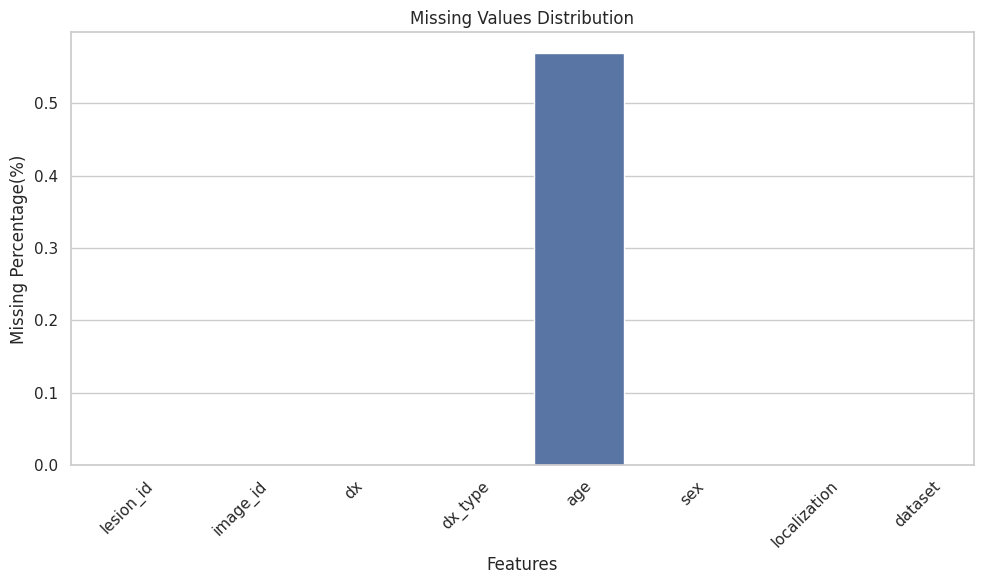

In [13]:
# ==========================================
# Missing Values Distribution Plot
# ==========================================

# Create figure
plt.figure(figsize=(10, 6))

# Plot missing values percentage
sns.barplot(
    x=missing_values.index,
    y=missing_values['Missing_Percentage']
)

# Customize Plot
plt.title('Missing Values Distribution')
plt.xlabel('Features')
plt.ylabel('Missing Percentage(%)')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_PATH, 'missing_value.png'),
    dpi=100
)
plt.show()

# 5	Duplicate Records Analysis